# Integrating mouse PBMC scRNA-seq samples with Harmony

**Data.** Five 10x Cell Ranger `filtered_feature_bc_matrix.h5` files (mm10),
mouse blood (PBMC) from female SPF mice: three young (9 weeks) and two old
(19 months). Sample details are in `data/metadata.txt`.

**Steps**

1. load the samples and their metadata;
2. quality control per sample, including red blood cells;
3. doublet removal;
4. normalise, pick highly variable genes, PCA;
5. look at the data before integration;
6. integrate with **Harmony** (batch = `sample`) and check the result;
7. cluster, find marker genes, give clusters provisional labels;
8. cell-type composition per sample;
9. save.

**Finding from step 2.** The two old samples (A170, A172) turn out to be
almost entirely red blood cells, so after QC only the three young samples
are left. The workflow still runs end to end, but **this data cannot compare
old and young blood** — see section 2.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
import harmonypy

for w in (FutureWarning, UserWarning, DeprecationWarning):
    warnings.filterwarnings("ignore", category=w)

DATA_DIR = Path("data")           # metadata.txt and pbmc/<sample>/filtered_feature_bc_matrix.h5
OUT_DIR = Path("results")         # everything the notebook writes (not tracked by git)
OUT_DIR.mkdir(exist_ok=True)
TISSUE = "pbmc"
SEED = 0

sc.settings.verbosity = 1
sc.settings.figdir = OUT_DIR
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(4.5, 4.5))

## 1. Load samples

Gene symbols are made unique (a few mm10 symbols repeat). Raw counts are kept
in `layers['counts']` before any transformation; the doublet detector needs
them.

In [2]:
meta = pd.read_csv(DATA_DIR / "metadata.txt", dtype=str)
meta = meta[meta["tissue"] == TISSUE].reset_index(drop=True)
display(meta)

adatas = {}
for r in meta.itertuples():
    a = sc.read_10x_h5(DATA_DIR / r.tissue / r.sample / "filtered_feature_bc_matrix.h5")
    a.var_names_make_unique()
    a.obs["sample"], a.obs["age"], a.obs["mouse"] = r.sample, r.age, "m" + r.mouse_id
    adatas[r.sample] = a

adata = ad.concat(adatas, index_unique="-", merge="same")
adata.obs["sample"] = adata.obs["sample"].astype("category")
adata.obs["age"] = pd.Categorical(adata.obs["age"], categories=["9w", "19M"])
adata.layers["counts"] = adata.X.copy()
adata

,sample,tissue,mouse_type,age,sex,mouse_id,serial
0,10x_A116,pbmc,SPF,9w,F,52,116
1,10x_A117,pbmc,SPF,9w,F,53,117
2,10x_A118,pbmc,SPF,9w,F,54,118
3,10x_A170,pbmc,SPF,19M,F,1,170
4,10x_A172,pbmc,SPF,19M,F,3,172


AnnData object with n_obs × n_vars = 14224 × 32285
    obs: 'sample', 'age', 'mouse'
    var: 'gene_ids', 'feature_types', 'genome'
    layers: 'counts'

## 2. Quality control

Per-cell metrics: total counts, genes detected, and the share of counts from
mitochondrial (`mt-`), ribosomal (`Rps`/`Rpl`) and haemoglobin (`Hba`/`Hbb`)
genes.

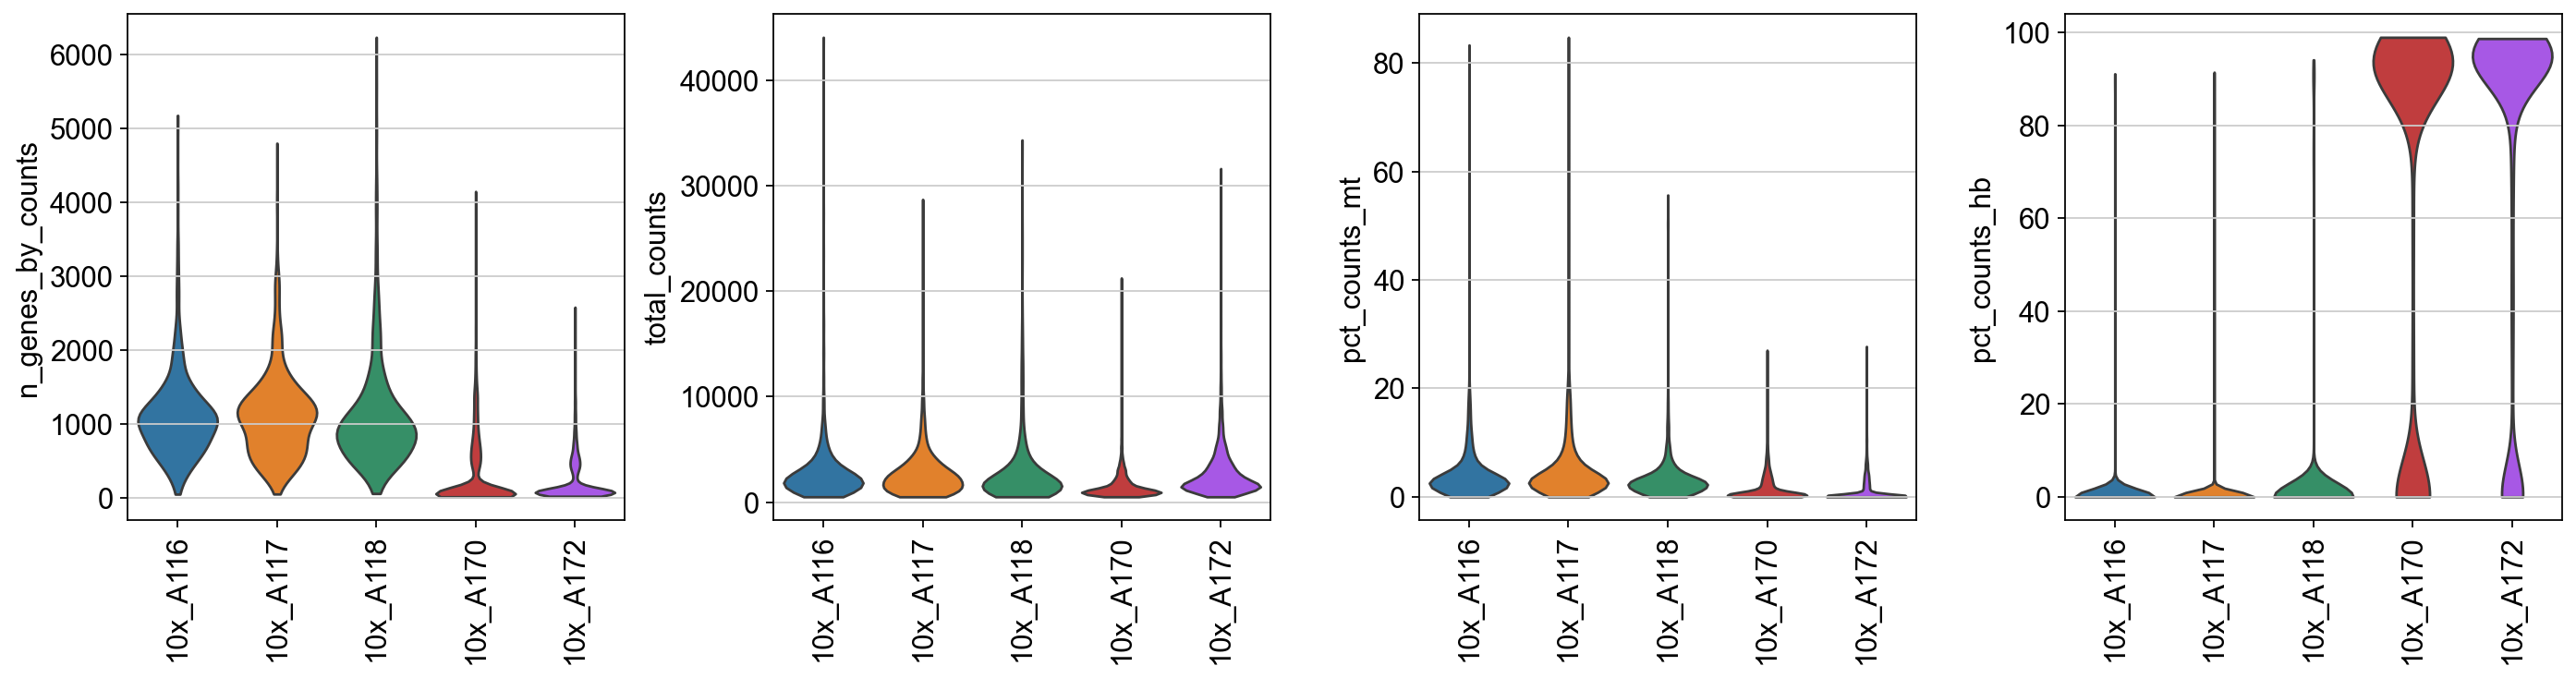

,n_cells,median_counts,median_genes,median_pct_mt,median_pct_hb,age
sample,,,,,,
10x_A116,951,2113.0,1036.0,2.7,0.000000,9w
10x_A117,858,2191.5,1072.5,3.0,0.000000,9w
10x_A118,1122,1804.0,916.5,2.4,0.000000,9w
10x_A170,4235,1110.0,62.0,0.5,92.599998,19M
10x_A172,7058,1977.5,84.0,0.1,94.599998,19M


In [3]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
adata.var["ribo"] = adata.var_names.str.match(r"^Rp[sl]\d")
adata.var["hb"] = adata.var_names.str.match(r"^Hb[ab]-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], inplace=True, percent_top=[20], log1p=True)

sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_hb"],
             groupby="sample", rotation=90, stripplot=False, multi_panel=True)
display(adata.obs.groupby("sample", observed=True)
        .agg(n_cells=("total_counts", "size"), median_counts=("total_counts", "median"),
             median_genes=("n_genes_by_counts", "median"), median_pct_mt=("pct_counts_mt", "median"),
             median_pct_hb=("pct_counts_hb", "median"), age=("age", "first")).round(1))

**Look at `median_pct_hb`.** In the old samples A170 and A172, about 90 % of
each cell's reads come from haemoglobin genes and a typical cell has fewer
than 100 genes detected. These are red blood cells (most likely red cells
were not lysed before loading). Leukocytes are only a small minority there.

**Filtering rule.** A cell is removed if any of these hold:

* **red blood cell**: more than 50 % haemoglobin reads and fewer than 500 genes;
* **outlier within its own sample**: more than 5 median absolute deviations
  (MAD) from the sample median on log counts, log genes or the top-20-gene
  share, or more than 5 MADs above the median mitochondrial share;
* more than 25 % mitochondrial reads, or fewer than 200 genes.

Samples left with fewer than `MIN_CELLS_PER_SAMPLE` cells are dropped.

In [4]:
MIN_CELLS_PER_SAMPLE = 100

def mad_outlier(x, nmads, upper_only=False):
    med = np.median(x)
    mad = np.median(np.abs(x - med)) * 1.4826
    hi = x > med + nmads * mad
    return hi if upper_only else hi | (x < med - nmads * mad)

o = adata.obs
outlier = pd.Series(False, index=adata.obs_names)
for s, idx in o.groupby("sample", observed=True).groups.items():
    x = o.loc[idx]
    outlier.loc[idx] = (mad_outlier(x["log1p_total_counts"], 5) | mad_outlier(x["log1p_n_genes_by_counts"], 5)
                        | mad_outlier(x["pct_counts_in_top_20_genes"], 5)
                        | mad_outlier(x["pct_counts_mt"], 5, upper_only=True)).to_numpy()
reasons = pd.DataFrame({
    "red blood cell": (o["pct_counts_hb"] > 50) & (o["n_genes_by_counts"] < 500),
    "MAD outlier": outlier,
    "> 25% mito": o["pct_counts_mt"] > 25,
    "< 200 genes": o["n_genes_by_counts"] < 200,
})
adata.obs["qc_fail"] = reasons.any(axis=1)
print("fraction of cells flagged, per reason:")
display(reasons.groupby(o["sample"], observed=True).mean()
        .join(adata.obs.groupby("sample", observed=True)["qc_fail"].mean().rename("removed (any)")).round(3))

n0 = adata.n_obs
adata = adata[~adata.obs["qc_fail"]].copy()
n = adata.obs["sample"].value_counts()
small = n[n < MIN_CELLS_PER_SAMPLE].index.tolist()
if small:
    print(f"dropping samples with < {MIN_CELLS_PER_SAMPLE} cells after QC: {small} (cells left: {n[small].to_dict()})")
    adata = adata[~adata.obs["sample"].isin(small)].copy()
adata.obs["sample"] = adata.obs["sample"].cat.remove_unused_categories()
sc.pp.filter_genes(adata, min_cells=10)
print(f"kept {adata.n_obs} / {n0} cells, {adata.n_vars} genes")
print("samples left per age:", adata.obs.drop_duplicates("sample")["age"].value_counts().to_dict())

fraction of cells flagged, per reason:


,red blood cell,MAD outlier,> 25% mito,< 200 genes,removed (any)
sample,,,,,
10x_A116,0.005,0.099,0.006,0.014,0.099
10x_A117,0.002,0.107,0.012,0.012,0.107
10x_A118,0.020,0.121,0.005,0.021,0.121
10x_A170,0.700,0.316,0.001,0.690,1.000
10x_A172,0.761,0.291,0.000,0.722,1.000


dropping samples with < 100 cells after QC: ['10x_A172', '10x_A170'] (cells left: {'10x_A172': 2, '10x_A170': 1})
kept 2609 / 14224 cells, 12843 genes
samples left per age: {'9w': 3}


## 3. Doublets

Scrublet simulates doublets from each sample's own cells and scores how
doublet-like every real cell is. It runs per sample on raw counts, because
doublets only form within one 10x channel. A fixed score threshold is used;
check that it sits in the dip of each histogram.

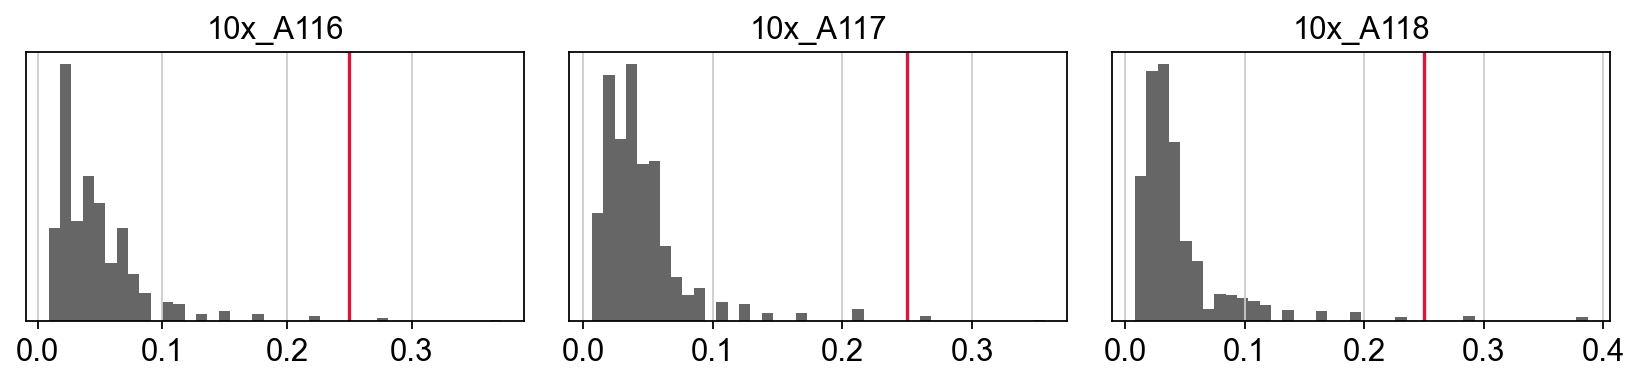

doublet fraction per sample: {'10x_A116': 0.005, '10x_A117': 0.005, '10x_A118': 0.009}
2592 cells after doublet removal


In [5]:
DOUBLET_THRESHOLD = 0.25
scores, calls = [], []
for s in adata.obs["sample"].cat.categories:
    m = (adata.obs["sample"] == s).to_numpy()
    a = sc.AnnData(adata.layers["counts"][m].copy(), obs=adata.obs.loc[m, []])
    sc.pp.scrublet(a, threshold=DOUBLET_THRESHOLD, random_state=SEED)
    scores.append(a.obs["doublet_score"]); calls.append(a.obs["predicted_doublet"])
adata.obs["doublet_score"] = pd.concat(scores).reindex(adata.obs_names)
adata.obs["predicted_doublet"] = pd.concat(calls).reindex(adata.obs_names).astype(bool)

samples = list(adata.obs["sample"].cat.categories)
fig, axes = plt.subplots(1, len(samples), figsize=(3.5 * len(samples), 2.6))
for ax, s in zip(np.atleast_1d(axes), samples):
    ax.hist(adata.obs.loc[adata.obs["sample"] == s, "doublet_score"], bins=40, color="0.4")
    ax.axvline(DOUBLET_THRESHOLD, color="crimson"); ax.set_title(s); ax.set_yticks([])
plt.tight_layout(); plt.show()

print("doublet fraction per sample:", adata.obs.groupby("sample", observed=True)["predicted_doublet"].mean().round(3).to_dict())
adata = adata[~adata.obs["predicted_doublet"]].copy()
print(f"{adata.n_obs} cells after doublet removal")

## 4. Normalise, highly variable genes, PCA

* normalise each cell to 10,000 counts, then `log1p` (raw counts stay in
  `layers['counts']`);
* 2,000 highly variable genes (`seurat_v3` on raw counts), chosen across
  samples (`batch_key="sample"`);
* PCA, 50 components.

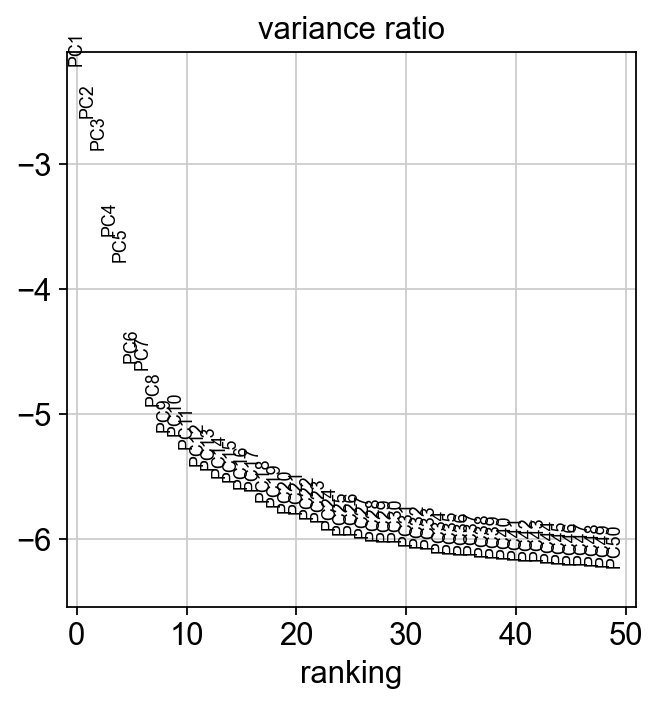

In [6]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata    # all genes, log-normalised, for marker plots

sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="sample")
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", random_state=SEED)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

## 5. Before integration

If the same cell types sit in separate islands per sample, there is a sample
(batch) effect to correct.

/Users/terooatt/miniconda3/envs/pbmc-integration/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


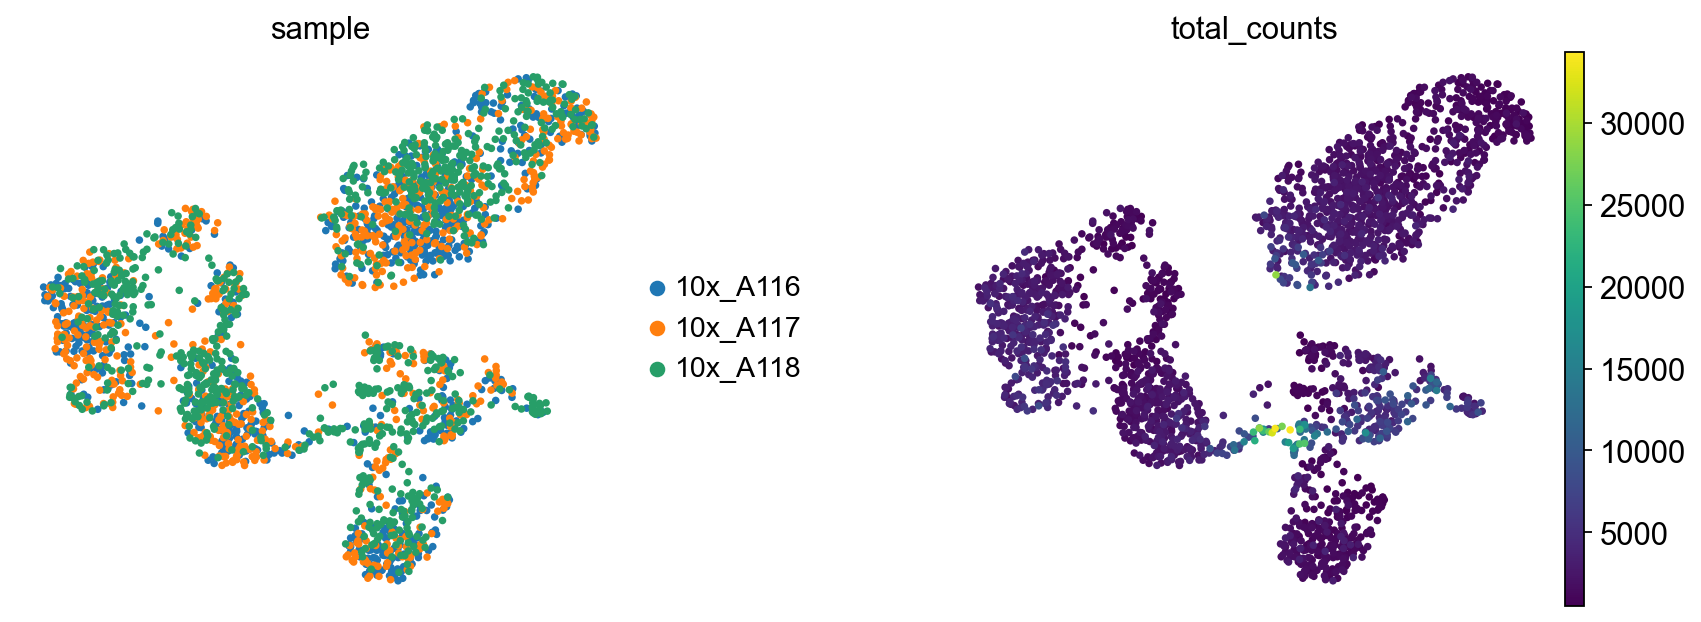

In [7]:
sc.pp.neighbors(adata, use_rep="X_pca", n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_before"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, "X_umap_before", color=["sample", "total_counts"], wspace=0.4)

## 6. Harmony

Harmony adjusts the PCs so that each cluster holds cells from every sample in
proportion. `theta` (default 2) sets how hard it pushes: raise it if samples
still separate, lower it if distinct cell types start to merge.

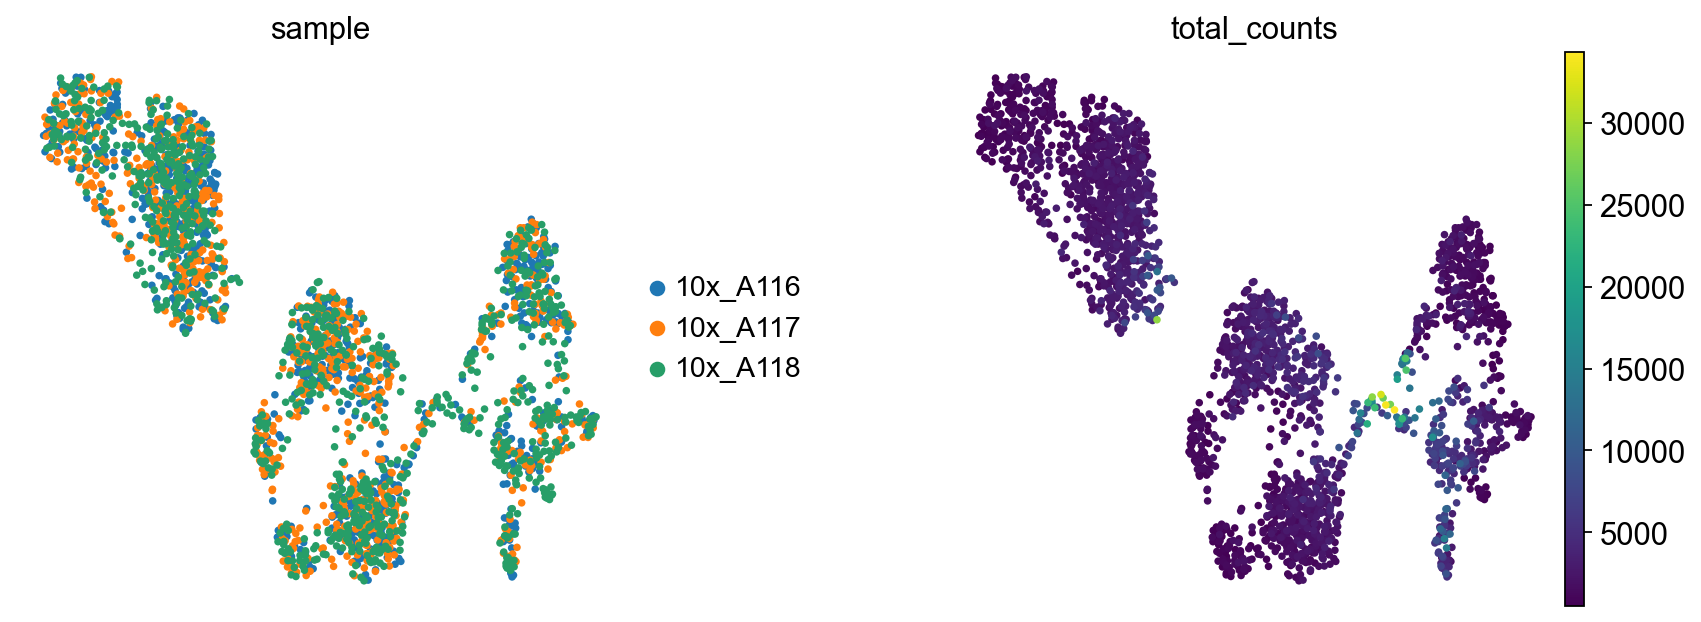

In [8]:
ho = harmonypy.run_harmony(adata.obsm["X_pca"][:, :30], adata.obs, "sample", theta=2,
                           max_iter_harmony=20, random_state=SEED, verbose=False)
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T

sc.pp.neighbors(adata, use_rep="X_pca_harmony", random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
sc.pl.umap(adata, color=["sample", "total_counts"], wspace=0.4)

**Did it work?** Two checks:

* **Sample mixing**: for each cell, the share of its 30 nearest neighbours
  that come from *other* samples, divided by what random mixing would give.
  1 = fully mixed, 0 = cells only neighbour their own sample.
* **Markers stay sharp**: known cell-type markers should still form compact
  islands. If they smear across the map, Harmony over-corrected.

sample mixing before Harmony: 0.89
sample mixing after Harmony:  0.99


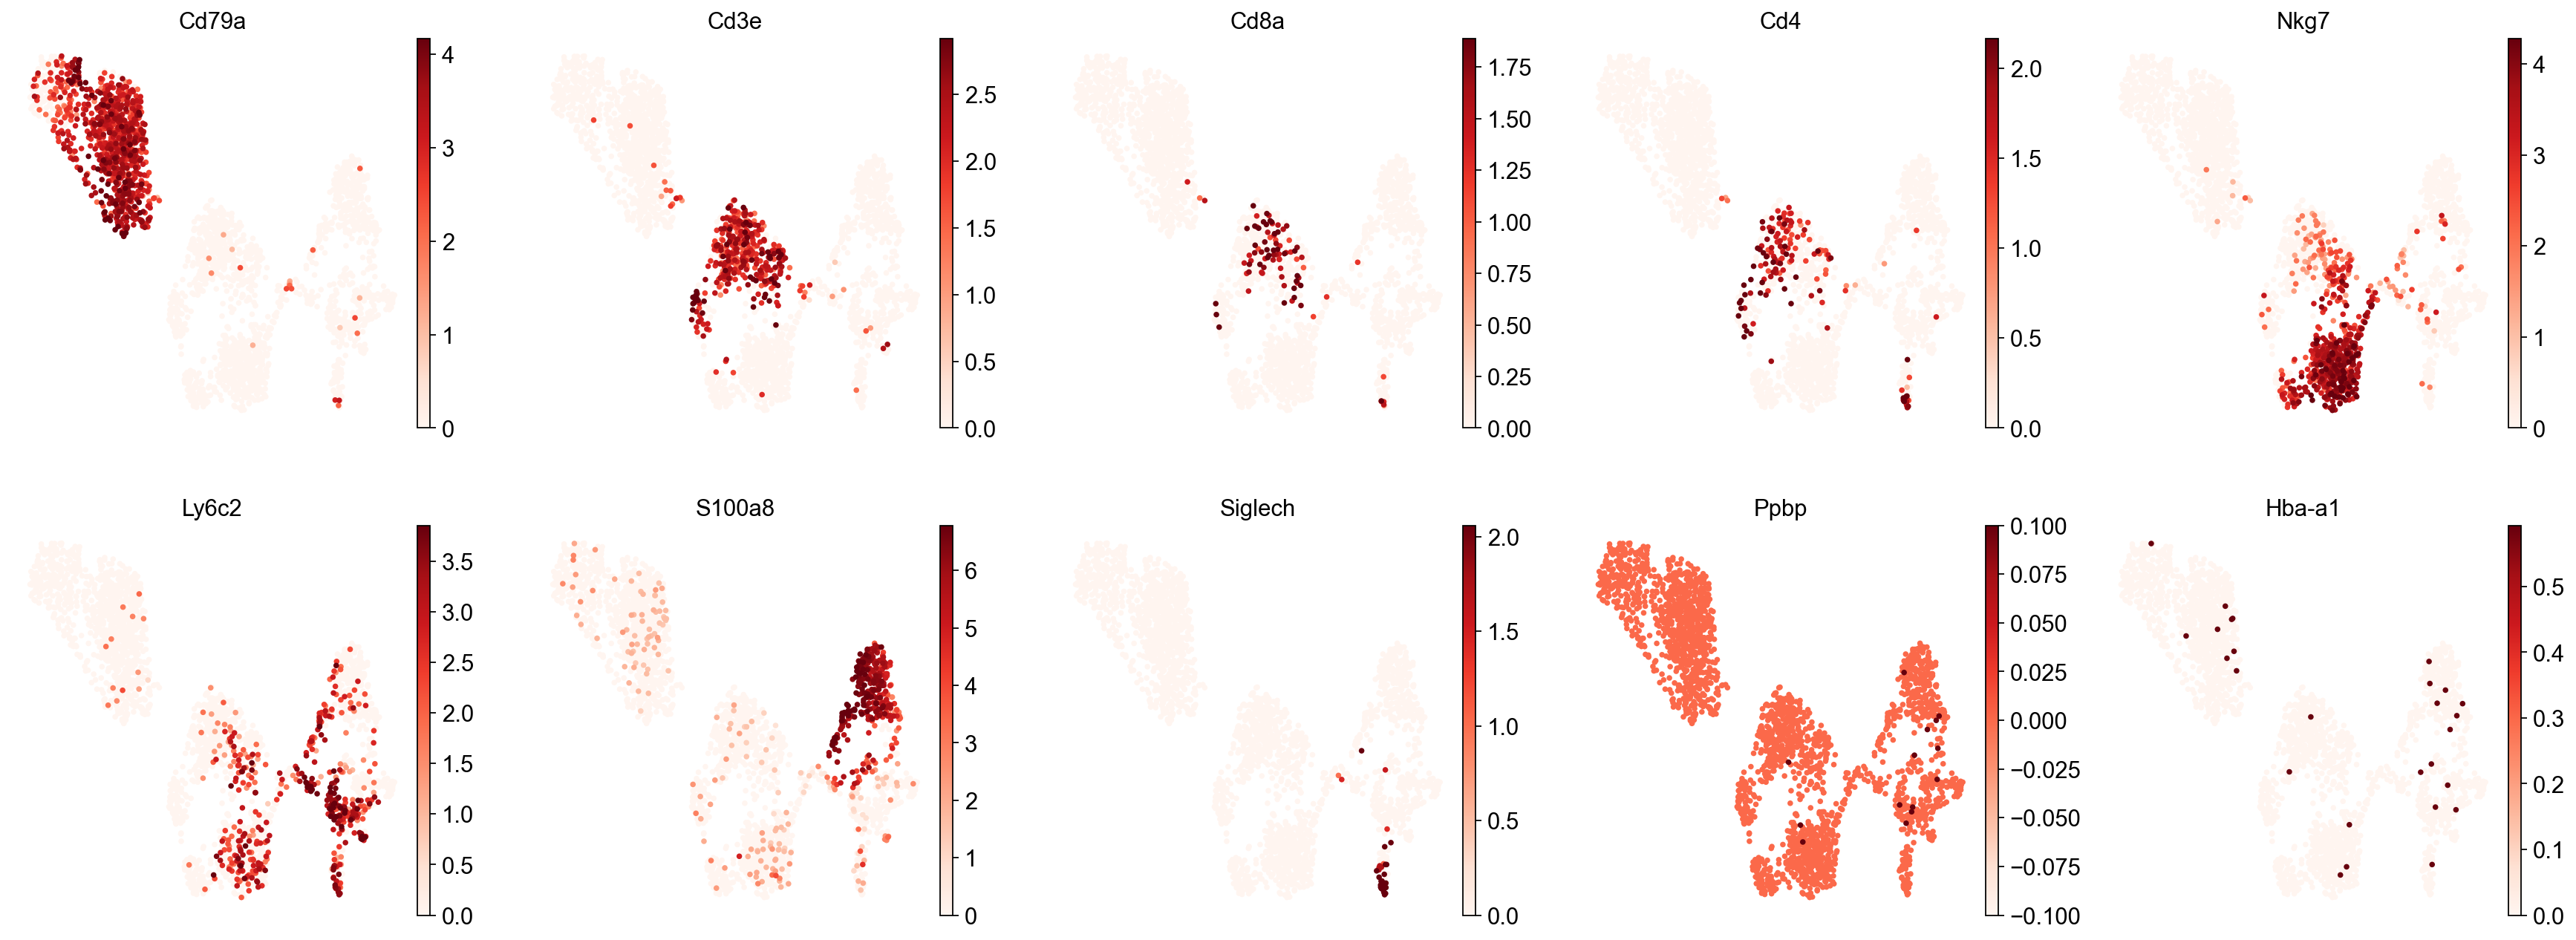

In [9]:
from sklearn.neighbors import NearestNeighbors

def sample_mixing(X, k=30):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    smp = adata.obs["sample"].cat.codes.to_numpy()
    observed = (smp[idx] != smp[:, None]).mean(1)
    share = pd.Series(smp).map(pd.Series(smp).value_counts(normalize=True)).to_numpy()
    return float(np.median(observed / (1 - share)))

print("sample mixing before Harmony:", round(sample_mixing(adata.obsm["X_pca"][:, :30]), 2))
print("sample mixing after Harmony: ", round(sample_mixing(adata.obsm["X_pca_harmony"]), 2))

MARKERS = ["Cd79a", "Cd3e", "Cd8a", "Cd4", "Nkg7", "Ly6c2", "S100a8", "Siglech", "Ppbp", "Hba-a1"]
sc.pl.umap(adata, color=[g for g in MARKERS if g in adata.raw.var_names], ncols=5, vmax="p99", cmap="Reds")

## 7. Clusters, markers and provisional labels

Leiden clustering on the Harmony neighbour graph, then the top marker genes
of each cluster (Wilcoxon test against all other cells).

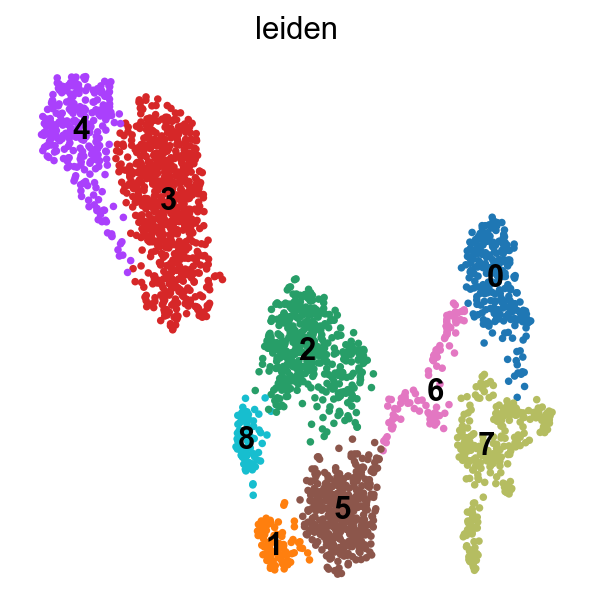

,top markers
group,
0,"Il1b, Il1r2, Dusp1, Hdc, S100a9, Srgn, S100a8,..."
1,"Gm2682, Sytl3, Malat1, Arsb, Gvin1, Ptprc, Ccl..."
2,"Tmsb10, Cd3e, Trbc2, Cd3d, Rplp0, Rplp1, Tpt1,..."
3,"Cd74, Cd79a, H2-Aa, H2-Ab1, H2-Eb1, Ly6d, Ighm..."
4,"Ebf1, Foxp1, Bach2, Malat1, Bank1, Aff3, Arhga..."
5,"Ccl5, Gzma, AW112010, Nkg7, Fcer1g, Lgals1, H2..."
6,"Hmgb2, Hmgn2, Gapdh, Sem1, H2afz, Prdx5, Dstn,..."
7,"Psap, Gpx1, Cst3, Ifitm3, Lyz2, Plac8, Ctsb, Ctss"
8,"Itk, Arhgap15, Skap1, Gm2682, Inpp4b, Themis, ..."


In [10]:
sc.tl.leiden(adata, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, random_state=SEED)
sc.pl.umap(adata, color="leiden", legend_loc="on data")

sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon")
markers = sc.get.rank_genes_groups_df(adata, None)
markers = markers[(markers["pvals_adj"] < 0.05) & (markers["logfoldchanges"] > 1)]
markers.to_csv(OUT_DIR / "markers_leiden.csv", index=False)
display(markers.groupby("group", observed=True).head(8).groupby("group", observed=True)["names"]
        .apply(", ".join).to_frame("top markers"))

Each cluster gets the blood cell type whose marker set scores highest. This
is a **starting point**: check every label against the marker table and the
dot plot, and rename or split clusters where they disagree (a small margin
over the second-best type is a warning sign).

,label,margin over 2nd,n_cells
leiden,,,
0,Neutrophil,2.74,270
1,NK cell,0.54,79
2,CD4 T cell,0.72,425
3,B cell,0.76,729
4,B cell,0.47,271
5,NK cell,1.15,367
6,Neutrophil,0.75,98
7,Classical monocyte,0.88,278
8,CD4 T cell,0.81,75


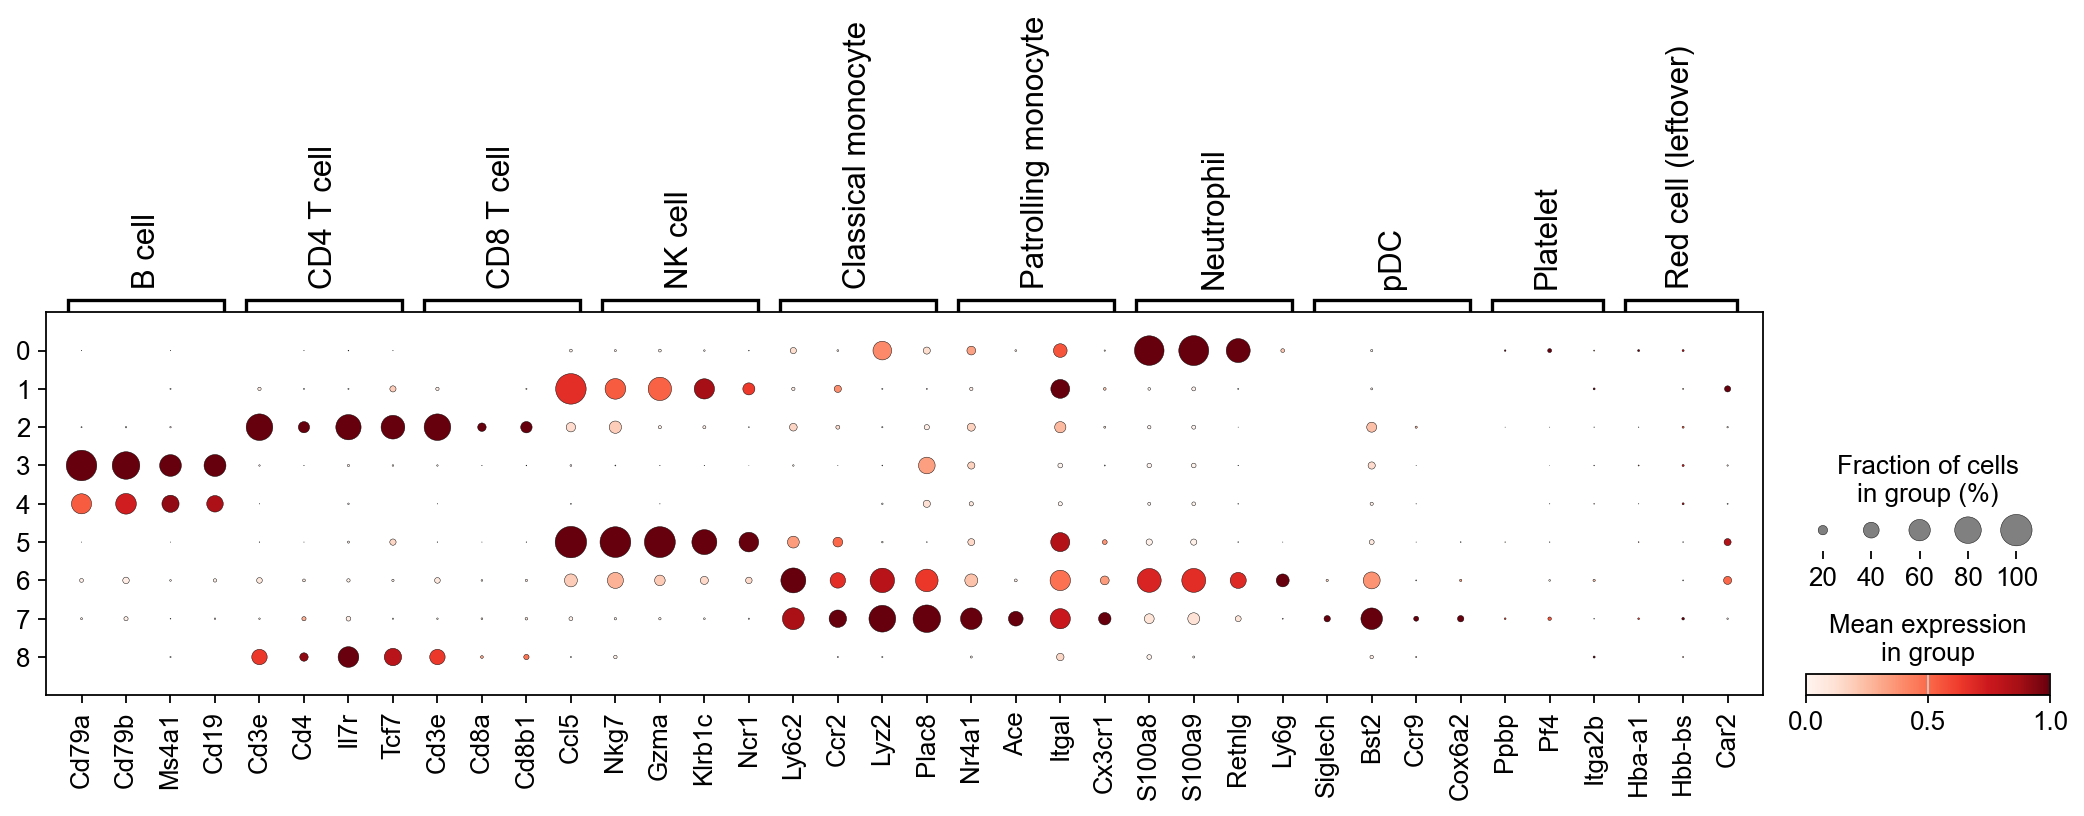

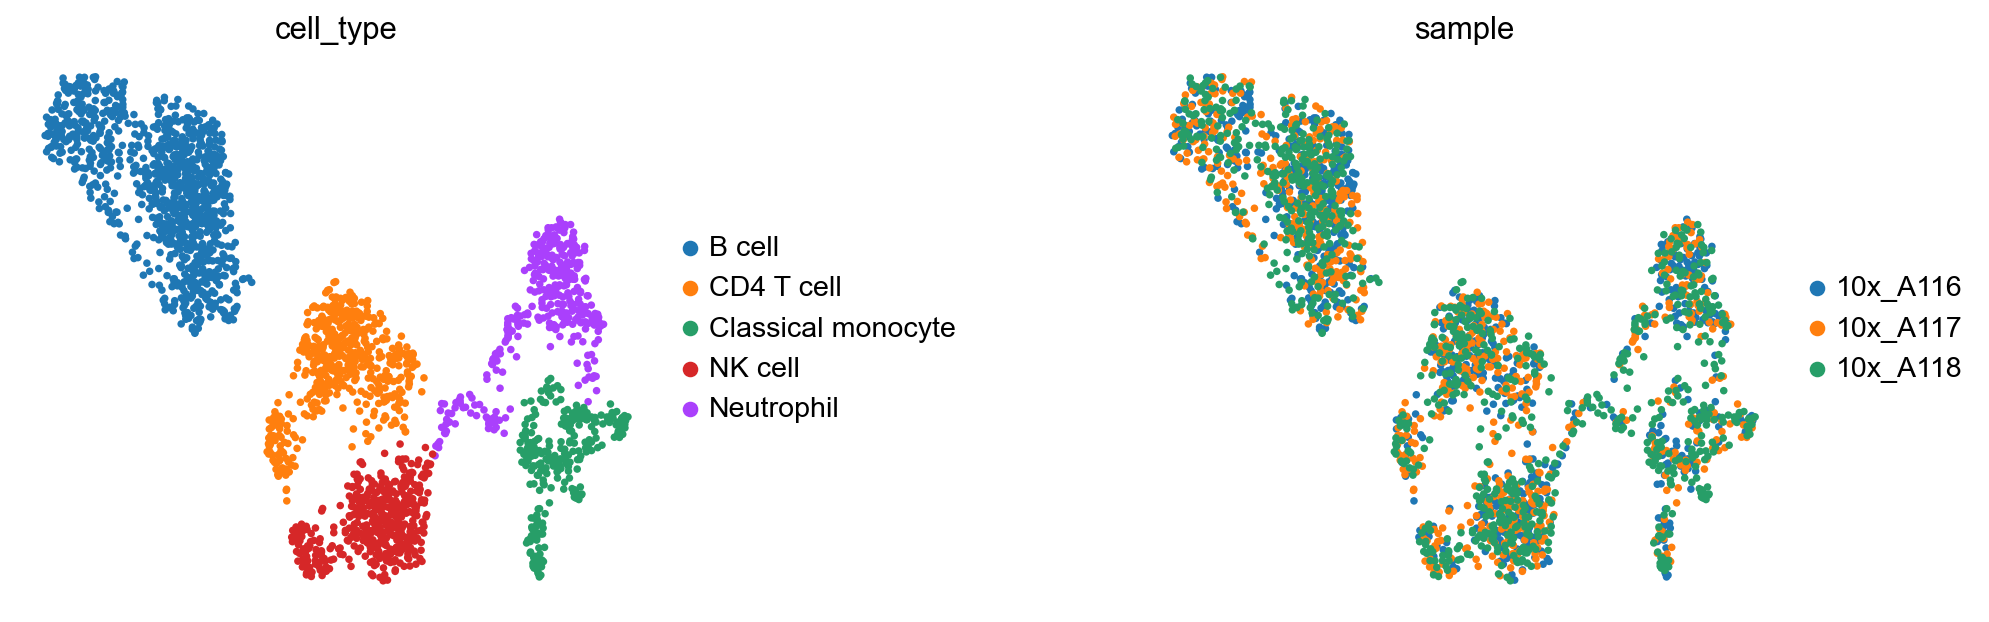

In [11]:
BLOOD = {
    "B cell":              ["Cd79a", "Cd79b", "Ms4a1", "Cd19"],
    "CD4 T cell":          ["Cd3e", "Cd4", "Il7r", "Tcf7"],
    "CD8 T cell":          ["Cd3e", "Cd8a", "Cd8b1", "Ccl5"],
    "NK cell":             ["Nkg7", "Gzma", "Klrb1c", "Ncr1"],
    "Classical monocyte":  ["Ly6c2", "Ccr2", "Lyz2", "Plac8"],
    "Patrolling monocyte": ["Nr4a1", "Ace", "Itgal", "Cx3cr1"],
    "Neutrophil":          ["S100a8", "S100a9", "Retnlg", "Ly6g"],
    "pDC":                 ["Siglech", "Bst2", "Ccr9", "Cox6a2"],
    "Platelet":            ["Ppbp", "Pf4", "Gp9", "Itga2b"],
    "Red cell (leftover)": ["Hba-a1", "Hbb-bs", "Alas2", "Car2"],
}
BLOOD = {k: [g for g in v if g in adata.raw.var_names] for k, v in BLOOD.items()}
for k, v in BLOOD.items():
    sc.tl.score_genes(adata, v, score_name=f"score_{k}", random_state=SEED)
scores = adata.obs.groupby("leiden", observed=True)[[f"score_{k}" for k in BLOOD]].mean()
scores.columns = list(BLOOD)
label = scores.idxmax(1)
margin = scores.apply(lambda r: r.nlargest(2).diff().abs().iloc[-1], axis=1)
adata.obs["cell_type"] = adata.obs["leiden"].map(label).astype("category")
display(pd.DataFrame({"label": label, "margin over 2nd": margin.round(2),
                      "n_cells": adata.obs["leiden"].value_counts()}))

sc.pl.dotplot(adata, BLOOD, groupby="leiden", standard_scale="var")
sc.pl.umap(adata, color=["cell_type", "sample"], wspace=0.6)

## 8. Composition per sample

Share of each cell type in each sample. Every sample is one mouse, so the
mouse is the unit of comparison, not the cell.

**Why there is no old-vs-young test here.** Both old samples were removed in
QC (red blood cells), so only young mice remain. Comparing ages needs old
samples with enough leukocytes — re-sequence after red-cell lysis, or use
another tissue from these mice (bone marrow, spleen and lung have old and
young samples with good quality).

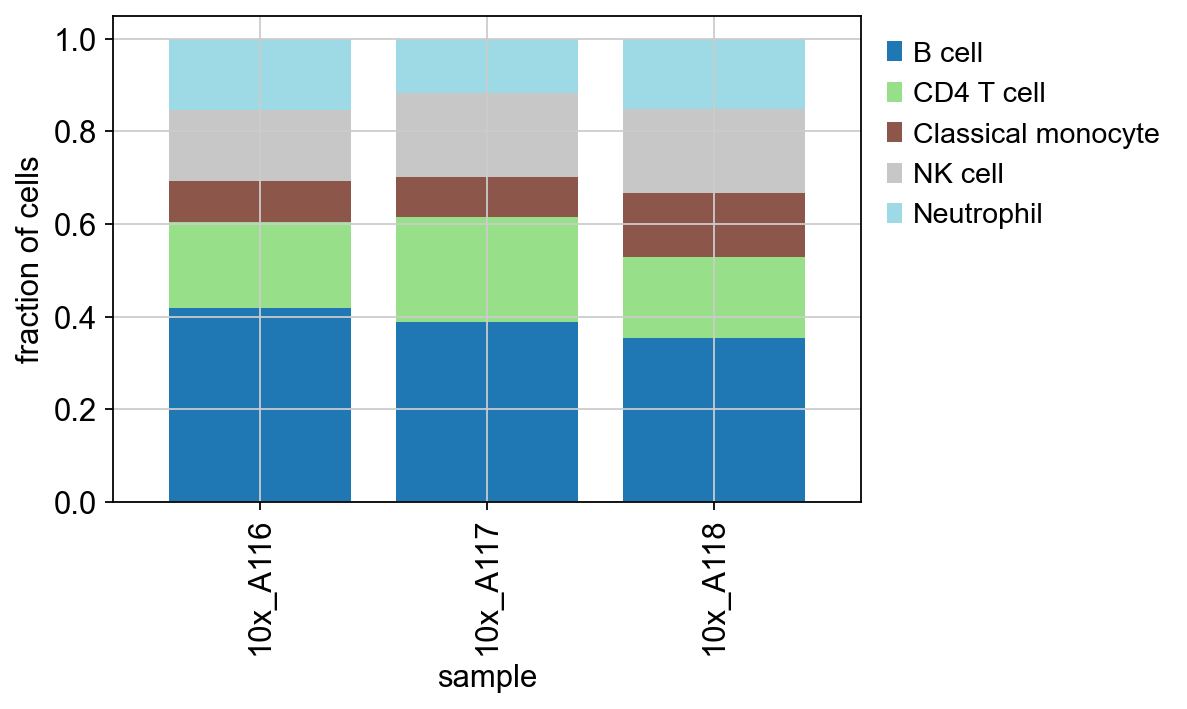

cell_type,B cell,CD4 T cell,Classical monocyte,NK cell,Neutrophil
sample,,,,,
10x_A116,0.419,0.185,0.089,0.154,0.154
10x_A117,0.388,0.227,0.087,0.181,0.117
10x_A118,0.355,0.173,0.139,0.181,0.151


In [12]:
comp = pd.crosstab(adata.obs["sample"].astype(str), adata.obs["cell_type"].astype(str), normalize="index")
comp.to_csv(OUT_DIR / "composition_by_sample.csv")
ax = comp.plot.bar(stacked=True, figsize=(6, 4), colormap="tab20", width=0.8)
ax.set_ylabel("fraction of cells"); ax.legend(bbox_to_anchor=(1, 1), frameon=False); plt.show()
display(comp.round(3))

## 9. Save

In [13]:
adata.write_h5ad(OUT_DIR / "pbmc_integrated.h5ad", compression="gzip")
print("wrote", OUT_DIR / "pbmc_integrated.h5ad")
adata

wrote results/pbmc_integrated.h5ad


AnnData object with n_obs × n_vars = 2592 × 12843
    obs: 'sample', 'age', 'mouse', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'qc_fail', 'doublet_score', 'predicted_doublet', 'leiden', 'score_B cell', 'score_CD4 T cell', 'score_CD8 T cell', 'score_NK cell', 'score_Classical monocyte', 'score_Patrolling monocyte', 'score_Neutrophil', 'score_pDC', 'score_Platelet', 'score_Red cell (leftover)', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'sample_col